In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("countries.csv")
df.head()

,Unnamed: 0,Country,GDP (Billions USD),Population (Millions),Unemployment Rate (%),Life Expectancy,Human Development Index (HDI),Exports (Billions USD)
0,0,USA,8116.26,1239,14.76,84.69,0.89,483.48
1,1,China,19063.57,290,12.91,72.63,0.76,300.32
2,2,India,14907.88,352,13.19,70.26,0.73,456.99
3,3,Japan,12374.51,1080,5.25,81.45,0.77,902.71
4,4,Germany,3964.35,1027,2.50,82.10,0.77,231.94


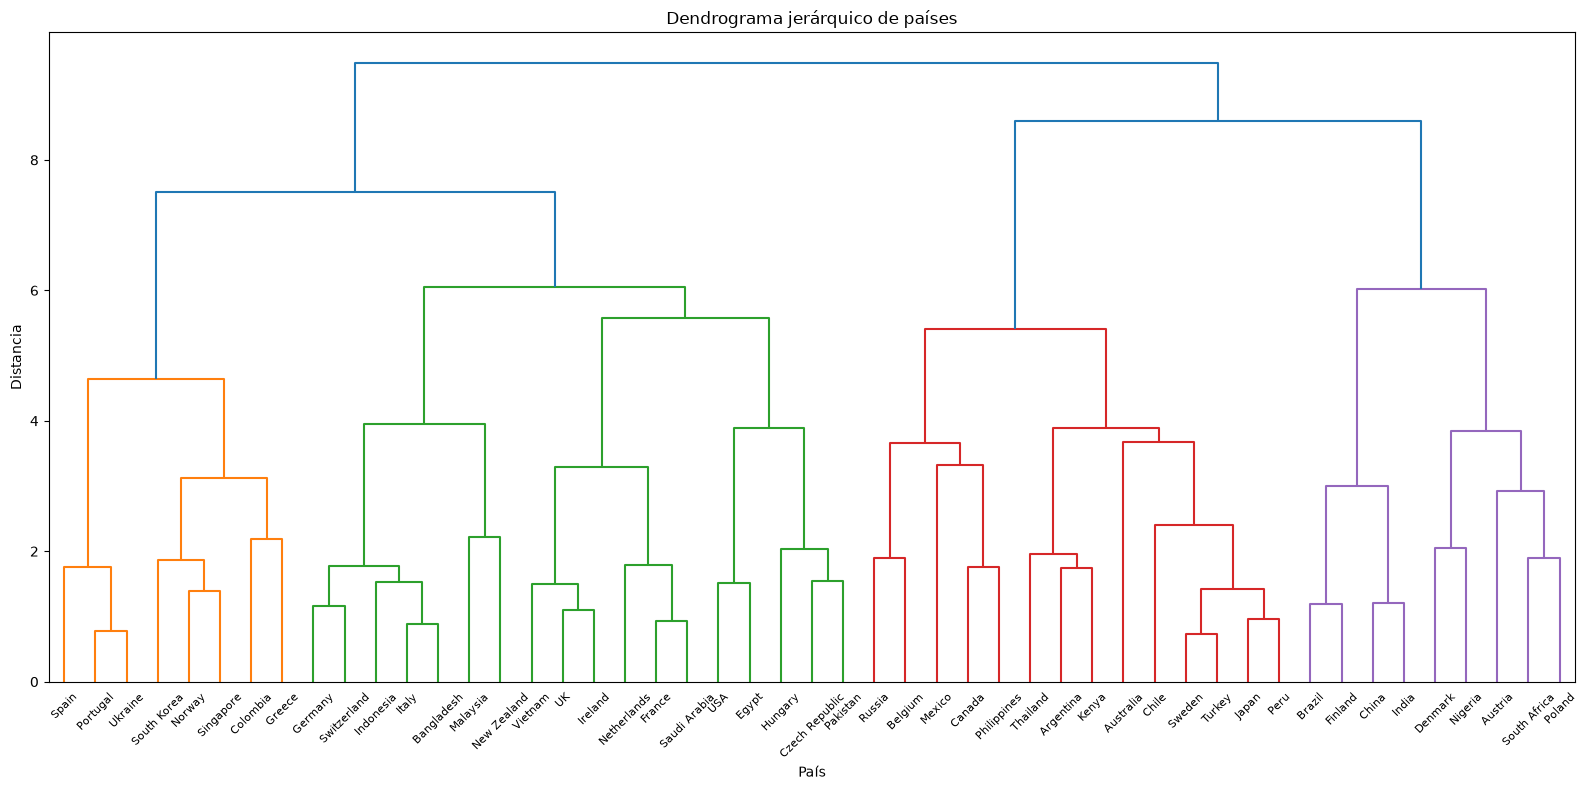

In [11]:
# Seleccionamos las variables relevantes para el clustering, eliminando el id y el propio país.
features = ["GDP (Billions USD)", "Population (Millions)", "Unemployment Rate (%)", "Life Expectancy", "Human Development Index (HDI)", "Exports (Billions USD)"]
X = df[features].copy()

# Convertimos todas las variables a numéricas
X = X.apply(pd.to_numeric, errors="coerce")

labels = df.loc[X.index, "Country"].astype(str).tolist()

# Estandarizamos las variables
X_scaled = StandardScaler().fit_transform(X)

# Realizamos el clustering jerárquico
Z = linkage(X_scaled, method="ward")

# Creamos el Linear Dendrogram
plt.figure(figsize=(16, 8))

dendrogram(
    Z,
    labels=labels,
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=None
)

plt.title("Dendrograma jerárquico de países")
plt.xlabel("País")
plt.ylabel("Distancia")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('Visualizacion2/Linear_Dendogram.png', dpi=300, bbox_inches="tight")
plt.show()
